<a href="https://colab.research.google.com/github/arzmtva/my-data-analysis/blob/main/Practical_7_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
from sklearn.datasets import load_wine

# Загружаем готовый датасет
wine = load_wine(as_frame=True)

# Создаём таблицу
df = wine.frame.copy()

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nКоличество классов:")
print(df["target"].value_counts())

print("\nНазвания классов:")
print(wine.target_names)


Размер датасета: (178, 14)

Первые 5 строк:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Названия столбцов:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']

Количество классов:
target
1    71
0    59
2    48
Name: count, dtype: int64

Названия классов:
['class_0' 'class_1' 'class_2']


In [2]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

# Целевой признак
X = df.drop(columns=["target"])
y = df["target"]

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("Количество признаков:", X.shape[1])


Обучающая выборка: (142, 13)
Тестовая выборка: (36, 13)
Количество признаков: 13


========== 1. НАСТРОЙКА МОДЕЛИ ==========
Лучшие параметры: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Лучший результат кросс-валидации: 0.9791

========== 2. СРАВНЕНИЕ МОДЕЛЕЙ ==========
Базовая модель Accuracy: 1.0
Настроенная модель Accuracy: 1.0
Изменение качества: 0.0

========== 3. ВАЖНОСТЬ ПРИЗНАКОВ ==========


,Признак,Важность
9,color_intensity,0.1876
6,flavanoids,0.1596
12,proline,0.1468
0,alcohol,0.1179
10,hue,0.1015
11,od280/od315_of_diluted_wines,0.0963
5,total_phenols,0.0415
4,magnesium,0.0401
1,malic_acid,0.0339
3,alcalinity_of_ash,0.0255


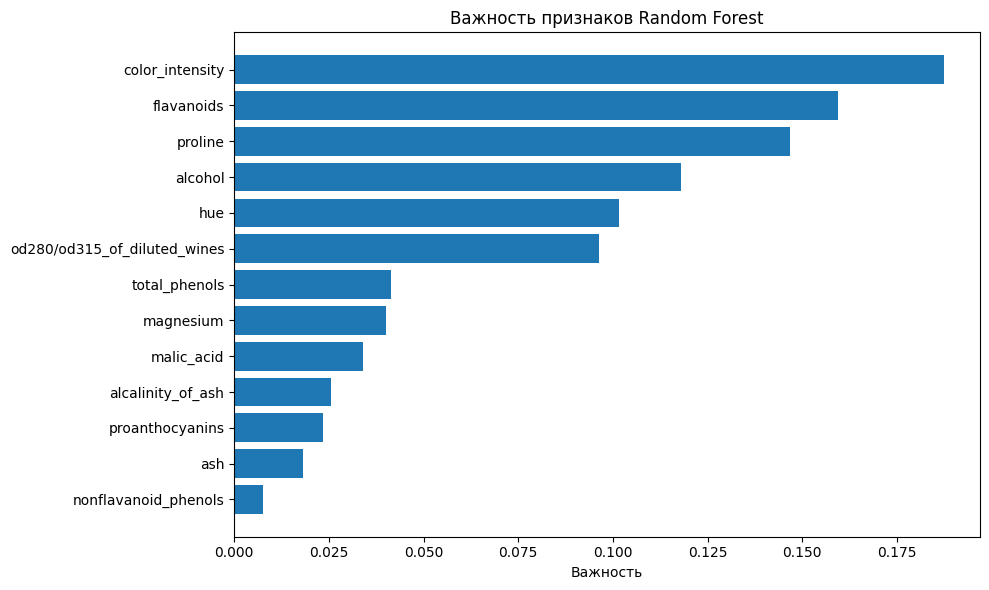


========== 4. ЭКСПЕРИМЕНТ С ПРИЗНАКАМИ ==========
Удалённые признаки: ['ash', 'nonflavanoid_phenols']
Оставшиеся признаки: 11


,Модель,Accuracy
0,Random Forest по умолчанию,1.0
1,Random Forest после настройки,1.0
2,Random Forest после удаления признаков,1.0


Разница после удаления признаков: 0.0


In [3]:

# ПРАКТИЧЕСКАЯ РАБОТА №3 — RANDOM FOREST, ВАРИАНТ B

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Подготовка данных
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. Базовая модель с параметрами по умолчанию
baseline = RandomForestClassifier(random_state=42)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

# 3. Подбор гиперпараметров с кросс-валидацией
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
best_pred = best_model.predict(X_test)
best_accuracy = accuracy_score(y_test, best_pred)

print("========== 1. НАСТРОЙКА МОДЕЛИ ==========")
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший результат кросс-валидации:",
      round(grid_search.best_score_, 4))

# 4. Сравнение моделей
print("\n========== 2. СРАВНЕНИЕ МОДЕЛЕЙ ==========")
print("Базовая модель Accuracy:", round(baseline_accuracy, 4))
print("Настроенная модель Accuracy:", round(best_accuracy, 4))
print("Изменение качества:", round(best_accuracy - baseline_accuracy, 4))

# 5. Важность признаков
importance_df = pd.DataFrame({
    "Признак": X.columns,
    "Важность": best_model.feature_importances_
}).sort_values("Важность", ascending=False)

print("\n========== 3. ВАЖНОСТЬ ПРИЗНАКОВ ==========")
display(importance_df.round(4))

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Признак"], importance_df["Важность"])
plt.gca().invert_yaxis()
plt.xlabel("Важность")
plt.title("Важность признаков Random Forest")
plt.tight_layout()
plt.show()

# 6. Удаляем 20% наименее важных признаков
n_remove = max(1, int(len(importance_df) * 0.2))
removed_features = importance_df.tail(n_remove)["Признак"].tolist()
kept_features = [col for col in X.columns if col not in removed_features]

reduced_model = RandomForestClassifier(
    random_state=42,
    **grid_search.best_params_
)

reduced_model.fit(X_train[kept_features], y_train)
reduced_pred = reduced_model.predict(X_test[kept_features])
reduced_accuracy = accuracy_score(y_test, reduced_pred)

# 7. Итоговая таблица
results = pd.DataFrame({
    "Модель": [
        "Random Forest по умолчанию",
        "Random Forest после настройки",
        "Random Forest после удаления признаков"
    ],
    "Accuracy": [
        baseline_accuracy,
        best_accuracy,
        reduced_accuracy
    ]
})

print("\n========== 4. ЭКСПЕРИМЕНТ С ПРИЗНАКАМИ ==========")
print("Удалённые признаки:", removed_features)
print("Оставшиеся признаки:", len(kept_features))
display(results.round(4))

print("Разница после удаления признаков:",
      round(reduced_accuracy - best_accuracy, 4))


### Вывод

В практической работе №3 я использовала алгоритм Random Forest и датасет Wine. С помощью GridSearchCV и 5-кратной кросс-валидации я подобрала гиперпараметры `n_estimators`, `max_depth` и `min_samples_leaf`.

Я сравнила базовую модель с настроенной моделью. Затем проанализировала важность признаков и удалила наименее важные из них.

После удаления признаков значение Accuracy **[почти не изменилось / уменьшилось / увеличилось]**. Эксперимент показал, что **[названия удалённых признаков]** можно **[исключить при сохранении качества / не исключать, поскольку качество ухудшилось]**.